In [9]:
import os
import numpy as np

PATH_EMB = "/home/hkerino/Documents/nextoso-dataset/alpha-earth_data"

In [14]:
sum_c = None
sum2_c = None
n_pixels = 0

for count,file in enumerate(os.listdir(PATH_EMB)):
    if not file.endswith(".npy"):
        continue

    embedding = np.load(os.path.join(PATH_EMB, file))  # (C, H, W)

    C, H, W = embedding.shape

    if sum_c is None:
        sum_c = np.zeros(C, dtype=np.float64)
        sum2_c = np.zeros(C, dtype=np.float64)

    embedding = embedding.astype(np.float64)

    # Somme par canal
    sum_c += embedding.sum(axis=(1, 2))

    # Somme des carrés par canal
    sum2_c += (embedding**2).sum(axis=(1, 2))

    n_pixels += H * W

# Statistiques finales
mean_c = sum_c / n_pixels
var_c = sum2_c / n_pixels - mean_c**2
std_c = np.sqrt(np.maximum(var_c, 0))

print("Mean shape:", mean_c.shape)
print("Std shape :", std_c.shape)


Mean shape: (64,)
Std shape : (64,)


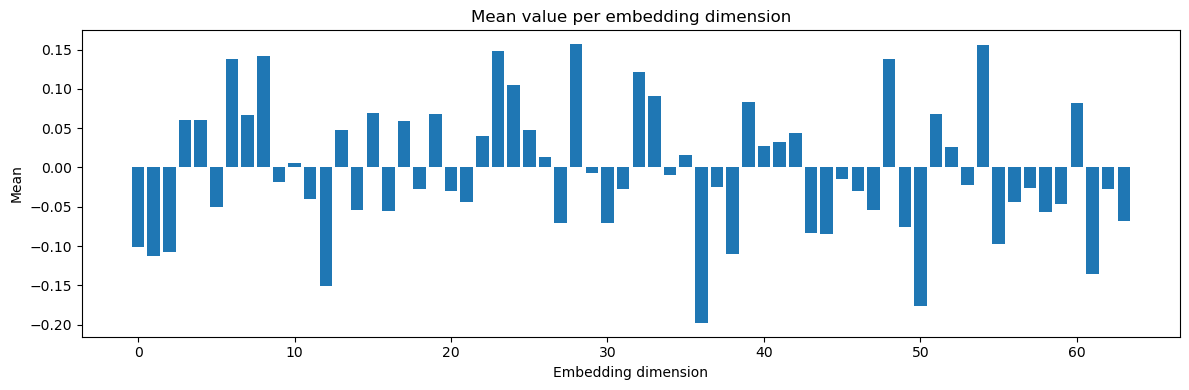

In [ ]:
from matplotlib import pyplot as plt

plt.figure(figsize=(12, 4))
plt.bar(np.arange(len(mean_c)), mean_c)
plt.xlabel("Embedding dimension")
plt.ylabel("Mean")
plt.title("Mean value per embedding dimension")
plt.tight_layout()
plt.show()

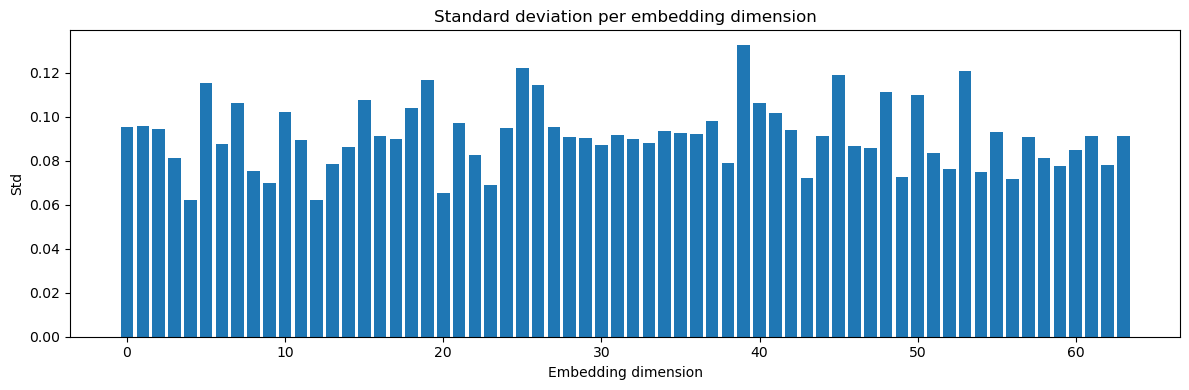

In [17]:
plt.figure(figsize=(12, 4))
plt.bar(np.arange(len(std_c)), std_c)
plt.xlabel("Embedding dimension")
plt.ylabel("Std")
plt.title("Standard deviation per embedding dimension")
plt.tight_layout()
plt.show()

In [72]:
import random 
import torch
from alpha_earth.dataset_alpha import alpha_earth_dataset
d_probas = alpha_earth_dataset(fold=None, label_type='probas')
d_maxclass = alpha_earth_dataset(fold=None, label_type="max_class")

item = random.randint(0, len(d_probas))
(emb_maxclass, label_maxclass), (emb_probas, label_probas) = (
    d_maxclass.__getitem__(item),
    d_probas.__getitem__(item),
)

assert (emb_probas == emb_maxclass).all()
assert (label_probas.argmax(dim=0) == label_maxclass).all(), "not equal"

AssertionError: not equal

In [73]:
print((label_probas.argmax(dim=0) == label_maxclass).all())
mask = label_probas.argmax(dim=0) == label_maxclass

n_false = (~mask).sum().item()
print(n_false)

idx_false = torch.where(~mask)

print(idx_false)

tensor(False)
59
(tensor([54, 54, 54, 54, 54, 54, 54, 55, 55, 55, 55, 55, 55, 55, 56, 56, 56, 56,
        56, 56, 57, 57, 57, 63, 63, 63, 63, 63, 64, 64, 64, 64, 64, 64, 64, 64,
        64, 64, 64, 65, 65, 65, 65, 65, 65, 66, 66, 67, 67, 68, 68, 68, 68, 69,
        69, 69, 70, 71, 71]), tensor([75, 76, 77, 78, 79, 80, 81, 75, 76, 77, 78, 79, 80, 81, 76, 77, 78, 79,
        80, 81, 79, 80, 81, 71, 72, 73, 74, 75, 26, 27, 28, 29, 30, 71, 72, 73,
        74, 75, 76, 27, 28, 29, 30, 31, 75, 30, 31, 24, 25, 24, 25, 26, 27, 26,
        27, 28, 27, 25, 26]))


In [74]:
pred_class = label_probas.argmax(dim=0)

mask = pred_class != label_maxclass

coords = torch.nonzero(mask)

print(f"{len(coords)} pixels différents")

for i, j in coords[:20]:
    print(
        f"({i}, {j}) : "
        f"argmax={pred_class[i, j].item()} "
        f"max_class={label_maxclass[i, j].item()}"
    )

59 pixels différents
(54, 75) : argmax=1 max_class=2
(54, 76) : argmax=1 max_class=2
(54, 77) : argmax=1 max_class=2
(54, 78) : argmax=1 max_class=2
(54, 79) : argmax=1 max_class=2
(54, 80) : argmax=1 max_class=2
(54, 81) : argmax=1 max_class=2
(55, 75) : argmax=1 max_class=2
(55, 76) : argmax=1 max_class=2
(55, 77) : argmax=1 max_class=2
(55, 78) : argmax=1 max_class=2
(55, 79) : argmax=1 max_class=2
(55, 80) : argmax=1 max_class=2
(55, 81) : argmax=1 max_class=2
(56, 76) : argmax=1 max_class=2
(56, 77) : argmax=1 max_class=2
(56, 78) : argmax=1 max_class=2
(56, 79) : argmax=1 max_class=2
(56, 80) : argmax=1 max_class=2
(56, 81) : argmax=1 max_class=2


In [66]:
label_probas[:,62,41]

tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.3049, 0.0000, 0.0000, 0.3049, 0.0784,
        0.3049, 0.0000, 0.0069, 0.0000, 0.0000, 0.0000, 0.0000])